# 03 — Arbre de régression CART implémenté from scratch

Code du modèle : `src/scratch_tree.py`.

## Pourquoi un arbre ?
L'effet d'une catastrophe n'a aucune raison d'être linéaire : il est probablement négligeable pour de petits chocs et brutal au-delà d'un seuil, et peut dépendre du niveau de développement (un pays riche reconstruit plus vite). Un arbre de régression capture **seuils et interactions** sans les spécifier à l'avance.

## Formulation
L'arbre partitionne $\mathbb{R}^p$ en régions $R_1,\dots,R_M$ et prédit la moyenne locale :
$$\hat f(\mathbf{x})=\sum_{m=1}^{M}c_m\,\mathbb{1}\{\mathbf{x}\in R_m\},\qquad c_m=\frac{1}{|R_m|}\sum_{i:\mathbf{x}_i\in R_m}y_i$$

**Objectif (impureté)** : somme des carrés des écarts dans chaque feuille, $\mathrm{SSE}(R)=\sum_{i\in R}(y_i-\bar y_R)^2=\sum y_i^2-\frac{(\sum y_i)^2}{|R|}$.

**Construction gloutonne récursive.** Trouver la partition globalement optimale est NP-difficile ; on choisit à chaque nœud la coupure $(j,s)$ qui maximise
$$\Delta(j,s)=\mathrm{SSE}(R)-\mathrm{SSE}(R_{x_j\le s})-\mathrm{SSE}(R_{x_j>s}).$$
Grâce aux sommes cumulées de $y$ et $y^2$ après tri selon $x_j$, toutes les coupures d'une variable sont évaluées en $O(n)$ (tri $O(n\log n)$). Coût d'un niveau : $O(p\,n\log n)$.

**Arrêt** : profondeur maximale, `min_samples_leaf` (taille minimale d'une feuille), pas de coupure améliorante. Ces hyperparamètres contrôlent le compromis biais–variance et sont choisis sur la validation.

In [1]:
import os, sys, time, warnings
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # métriques autorisées
from src import data_prep as dp
from src.plot_style import *
setup()
SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 3)
from src.scratch_tree import RegressionTreeScratch, partial_dependence
from src.scratch_linear import LinearRegressionScratch
panel = dp.build_panel()
s = dp.make_splits(panel)
F = s.features

## 1. Vérification sur un problème jouet
Fonction en escalier bruitée : un arbre de profondeur 2 doit retrouver les trois paliers et les seuils 0,3 et 0,7.

x <= 0.299  (n=400)
|   x <= 0.294  (n=121)
|   |   -> ŷ = 0.93  (n=119)
|   x >  0.294
|   |   -> ŷ = 1.29  (n=2)
x >  0.299
|   x <= 0.700  (n=279)
|   |   -> ŷ = 4.01  (n=162)
|   x >  0.700
|   |   -> ŷ = 2.00  (n=117)



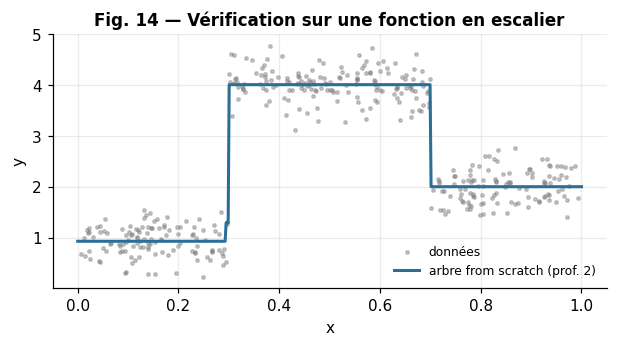

In [2]:
rng = np.random.default_rng(SEED)
x = rng.uniform(0, 1, 400); y = np.where(x < 0.3, 1.0, np.where(x < 0.7, 4.0, 2.0)) + rng.normal(0, 0.3, 400)
toy = RegressionTreeScratch(max_depth=2).fit(x[:, None], y)
print(toy.to_text(["x"], max_depth=2))
grid = np.linspace(0, 1, 500)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.scatter(x, y, s=5, alpha=0.4, color=C_NEUTRAL, label="données")
ax.plot(grid, toy.predict(grid[:, None]), color=C_SCRATCH, lw=2, label="arbre from scratch (prof. 2)")
ax.set(title="Fig. 14 — Vérification sur une fonction en escalier", xlabel="x", ylabel="y"); ax.legend(fontsize=8)
save(fig, "fig14_toy_tree.png"); plt.show()

## 2. Choix des hyperparamètres (validation)

In [3]:
depths = list(range(1, 13)); leaves = [5, 10, 20, 50, 100, 200]
grid_val = np.zeros((len(leaves), len(depths))); rows = []
for a, L in enumerate(leaves):
    for b, d in enumerate(depths):
        t = RegressionTreeScratch(max_depth=d, min_samples_leaf=L).fit(s.X_train, s.y_train)
        r_tr = mean_squared_error(s.y_train, t.predict(s.X_train)) ** .5
        r_va = mean_squared_error(s.y_val, t.predict(s.X_val)) ** .5
        grid_val[a, b] = r_va; rows.append((d, L, r_tr, r_va, t.n_leaves()))
gs = pd.DataFrame(rows, columns=["max_depth", "min_samples_leaf", "rmse_train", "rmse_val", "n_leaves"])
best = gs.loc[gs.rmse_val.idxmin()]
BEST_D, BEST_L = int(best.max_depth), int(best.min_samples_leaf)
gs.to_csv("../results/tree_grid.csv", index=False)
print(f"Meilleur : max_depth={BEST_D}, min_samples_leaf={BEST_L}, RMSE val={best.rmse_val:.3f}")

Meilleur : max_depth=8, min_samples_leaf=100, RMSE val=4.080


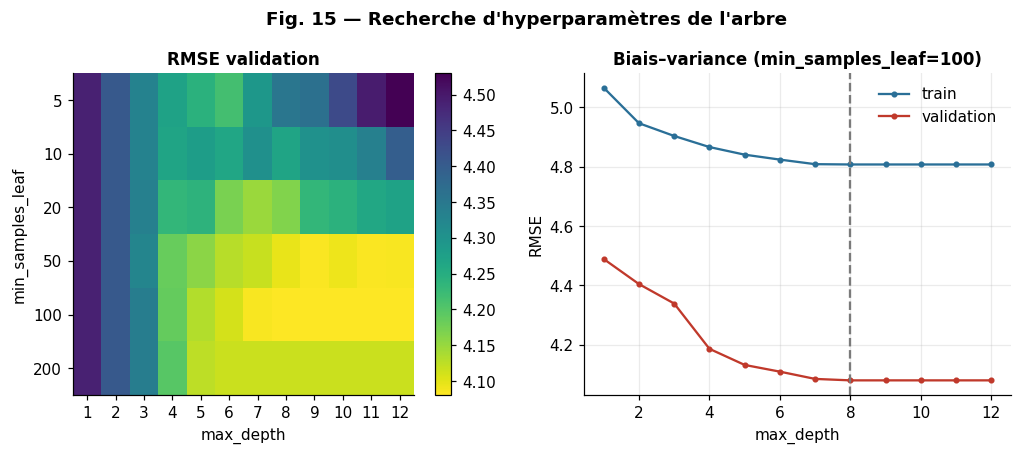

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
im = axes[0].imshow(grid_val, cmap="viridis_r", aspect="auto")
axes[0].set_xticks(range(len(depths))); axes[0].set_xticklabels(depths)
axes[0].set_yticks(range(len(leaves))); axes[0].set_yticklabels(leaves)
axes[0].set(title="RMSE validation", xlabel="max_depth", ylabel="min_samples_leaf"); axes[0].grid(False)
fig.colorbar(im, ax=axes[0])
sub = gs[gs.min_samples_leaf == BEST_L]
axes[1].plot(sub.max_depth, sub.rmse_train, "o-", ms=3, color=C_SCRATCH, label="train")
axes[1].plot(sub.max_depth, sub.rmse_val, "o-", ms=3, color=C_ACCENT, label="validation")
axes[1].axvline(BEST_D, color=C_NEUTRAL, ls="--")
axes[1].set(title=f"Biais–variance (min_samples_leaf={BEST_L})", xlabel="max_depth", ylabel="RMSE"); axes[1].legend()
fig.suptitle("Fig. 15 — Recherche d'hyperparamètres de l'arbre", fontweight="bold", y=1.03)
save(fig, "fig15_tree_grid.png"); plt.show()

Au-delà de la profondeur optimale, l'erreur d'entraînement continue de baisser alors que l'erreur de validation remonte : **sur-apprentissage** classique. Des feuilles trop petites (5–10 observations) amplifient la variance.

## 3. Modèle final et ablation

In [5]:
tree = RegressionTreeScratch(max_depth=BEST_D, min_samples_leaf=BEST_L).fit(s.X_train, s.y_train)
ctrl = [F.index(f) for f in dp.CONTROL_FEATURES]
tree_ctrl = RegressionTreeScratch(max_depth=BEST_D, min_samples_leaf=BEST_L).fit(s.X_train[:, ctrl], s.y_train)
print(f"profondeur = {tree.depth()}, feuilles = {tree.n_leaves()}")
def metrics(y, p): return dict(MAE=mean_absolute_error(y, p), RMSE=mean_squared_error(y, p) ** .5, R2=r2_score(y, p))
rows = []
for split in ["train", "val", "test", "stress"]:
    X, y = getattr(s, f"X_{split}"), getattr(s, f"y_{split}")
    rows.append({"split": split, "modèle": "Arbre (contrôles seuls)", **metrics(y, tree_ctrl.predict(X[:, ctrl]))})
    rows.append({"split": split, "modèle": "Arbre (contrôles + catastrophes)", **metrics(y, tree.predict(X))})
perf = pd.DataFrame(rows).set_index(["split", "modèle"]); perf.to_csv("../results/tree_performance.csv"); perf

profondeur = 8, feuilles = 40


MAE   RMSE     R2
split  modèle                                               
train  Arbre (contrôles seuls)           3.329  4.810  0.166
       Arbre (contrôles + catastrophes)  3.324  4.807  0.167
val    Arbre (contrôles seuls)           2.890  4.084  0.286
       Arbre (contrôles + catastrophes)  2.888  4.080  0.288
test   Arbre (contrôles seuls)           2.143  3.316  0.152
       Arbre (contrôles + catastrophes)  2.138  3.314  0.153
stress Arbre (contrôles seuls)           6.560  7.937 -1.157
       Arbre (contrôles + catastrophes)  6.571  7.927 -1.151

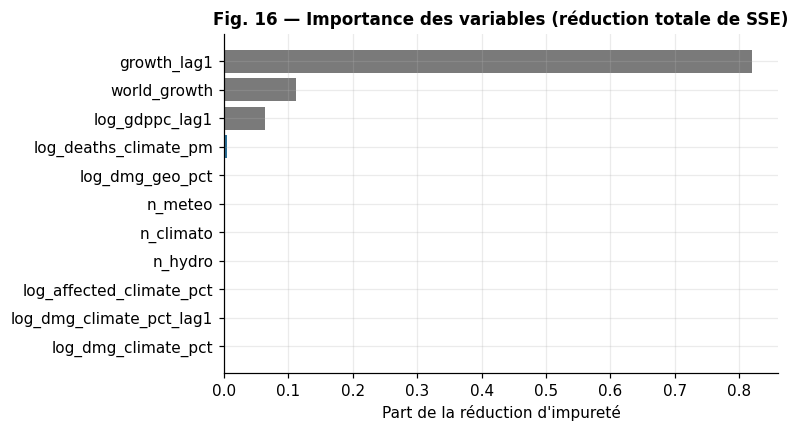

Part totale des variables de catastrophes : 0.5%


In [6]:
imp = pd.Series(tree.feature_importances_, index=F).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(imp.index, imp.values, color=[C_CLIMATE if f in dp.DISASTER_FEATURES else C_NEUTRAL for f in imp.index])
ax.set(title="Fig. 16 — Importance des variables (réduction totale de SSE)", xlabel="Part de la réduction d'impureté")
save(fig, "fig16_tree_importance.png"); plt.show()
print(f"Part totale des variables de catastrophes : {imp[dp.DISASTER_FEATURES].sum():.1%}")

In [7]:
def unscale(j, v): return v * s.std[j] + s.mean[j]
print(tree.to_text(F, max_depth=3, unscale=unscale))

growth_lag1 <= 4.950  (n=5174)
|   growth_lag1 <= -6.442  (n=3234)
|   |   log_gdppc_lag1 <= 6.761  (n=202)
|   |   |   -> ŷ = 0.08  (n=102)
|   |   log_gdppc_lag1 >  6.761
|   |   |   -> ŷ = -1.35  (n=100)
|   growth_lag1 >  -6.442
|   |   growth_lag1 <= 2.420  (n=3032)
|   |   |   -> ŷ = 2.26  (n=1646)
|   |   growth_lag1 >  2.420
|   |   |   -> ŷ = 3.57  (n=1386)
growth_lag1 >  4.950
|   growth_lag1 <= 10.607  (n=1940)
|   |   growth_lag1 <= 7.292  (n=1558)
|   |   |   -> ŷ = 4.51  (n=963)
|   |   growth_lag1 >  7.292
|   |   |   -> ŷ = 5.56  (n=595)
|   growth_lag1 >  10.607
|   |   growth_lag1 <= 16.350  (n=382)
|   |   |   -> ŷ = 7.80  (n=267)
|   |   growth_lag1 >  16.350
|   |   |   -> ŷ = 10.01  (n=115)



## 4. Forme de l'effet : dépendance partielle
On fait varier les dommages climatiques de l'année $t$ sur une grille, les autres variables gardant leurs valeurs observées (échantillon de test), et on moyenne les prédictions. On compare la forme apprise par l'arbre (non linéaire) et par le modèle linéaire.

arbre (7, 20) : RMSE val = 4.148, part des catastrophes dans l'importance = 7.0%


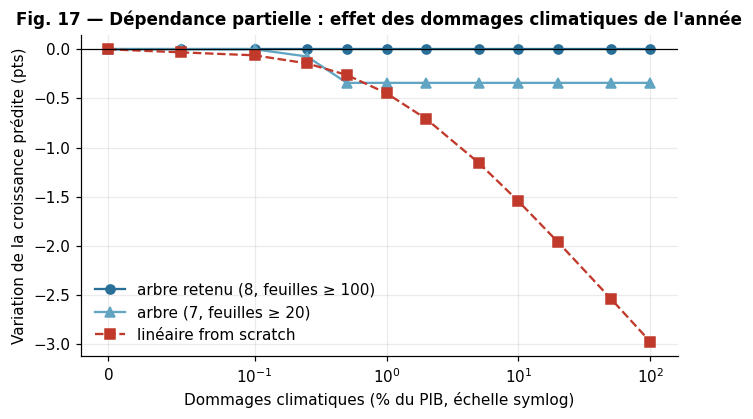

,dommages %PIB,arbre retenu,"arbre (7,20)",linéaire
0,0.00,0.0,0.00,0.00
1,0.05,0.0,0.00,-0.03
2,0.10,0.0,0.00,-0.06
3,0.25,0.0,-0.07,-0.14
4,0.50,0.0,-0.34,-0.26
5,1.00,0.0,-0.34,-0.45
6,2.00,0.0,-0.34,-0.71
7,5.00,0.0,-0.34,-1.15
8,10.00,0.0,-0.34,-1.55
9,20.00,0.0,-0.34,-1.96


In [8]:
lin = LinearRegressionScratch(solver="normal").fit(s.X_train, s.y_train)
j = F.index("log_dmg_climate_pct")
pct = np.array([0, 0.05, 0.1, 0.25, 0.5, 1, 2, 5, 10, 20, 50, 100])
grid = (np.log1p(pct) - s.mean[j]) / s.std[j]
pd_tree = partial_dependence(tree, s.X_test, j, grid)
pd_lin = partial_dependence(lin, s.X_test, j, grid)
# arbre moins contraint (feuilles de 20) : plus de variance, mais capable d'isoler les chocs rares
tree20 = RegressionTreeScratch(max_depth=7, min_samples_leaf=20).fit(s.X_train, s.y_train)
pd_t20 = partial_dependence(tree20, s.X_test, j, grid)
print(f"arbre (7, 20) : RMSE val = {mean_squared_error(s.y_val, tree20.predict(s.X_val))**.5:.3f}, "
      f"part des catastrophes dans l'importance = {tree20.feature_importances_[[F.index(f) for f in dp.DISASTER_FEATURES]].sum():.1%}")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(pct, pd_tree - pd_tree[0], "o-", color=C_SCRATCH, label=f"arbre retenu ({BEST_D}, feuilles ≥ {BEST_L})")
ax.plot(pct, pd_t20 - pd_t20[0], "^-", color="#61a5c2", label="arbre (7, feuilles ≥ 20)")
ax.plot(pct, pd_lin - pd_lin[0], "s--", color=C_ACCENT, label="linéaire from scratch")
ax.set_xscale("symlog", linthresh=0.1); ax.axhline(0, color="k", lw=0.8)
ax.set(title="Fig. 17 — Dépendance partielle : effet des dommages climatiques de l'année",
       xlabel="Dommages climatiques (% du PIB, échelle symlog)", ylabel="Variation de la croissance prédite (pts)")
ax.legend(); save(fig, "fig17_partial_dependence.png"); plt.show()
pd.DataFrame({"dommages %PIB": pct, "arbre retenu": pd_tree - pd_tree[0], "arbre (7,20)": pd_t20 - pd_t20[0], "linéaire": pd_lin - pd_lin[0]}).round(2)

**Résultat important (et négatif) pour l'arbre.** L'arbre retenu sur la validation (feuilles ≥ 100) **n'utilise quasiment pas les catastrophes** : sa dépendance partielle est plate et l'ablation ne change presque rien. Ce n'est pas un bug mais une limite structurelle : seuls 3,7 % des pays-années subissent un choc > 1 % du PIB. Une feuille de 100 observations ne peut pas isoler ces cas rares, et la réduction de SSE qu'ils apportent est éclipsée par celle de l'inertie de la croissance (`growth_lag1`, ~60 % de l'importance). Un arbre moins contraint (feuilles ≥ 20) les utilise et retrouve un effet négatif en marches pour les gros chocs, mais il généralise moins bien (RMSE de validation plus élevée).

Le modèle linéaire, lui, **partage l'information** entre toutes les observations via un seul coefficient : il est plus efficace statistiquement pour détecter un effet moyen modéré porté par une variable rare. C'est la raison pour laquelle il bat l'arbre sur le test et constitue le modèle de référence pour répondre à la question.

## 5. Coût de calcul

In [9]:
rng = np.random.default_rng(SEED); rows = []
for n in [500, 1000, 2000, 3500, 5174]:
    idx = rng.choice(len(s.y_train), n, replace=False)
    t = time.perf_counter(); RegressionTreeScratch(max_depth=BEST_D, min_samples_leaf=BEST_L).fit(s.X_train[idx], s.y_train[idx])
    rows.append((n, time.perf_counter() - t))
tim = pd.DataFrame(rows, columns=["n", "temps (s)"]); tim

,n,temps (s)
0,500,0.003
1,1000,0.009
2,2000,0.020
3,3500,0.044
4,5174,0.073
